In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder
import numpy as np
import matplotlib.pyplot as plt
df=pd.read_csv('drug200.csv')


In [5]:
df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


In [6]:
df.dropna(inplace=True)
df=df.drop_duplicates()
df.duplicated().sum()
df.isnull().sum()


Age            0
Sex            0
BP             0
Cholesterol    0
Na_to_K        0
Drug           0
dtype: int64

In [7]:
le = LabelEncoder()

df['Sex'] = le.fit_transform(df['Sex'])
df['BP'] = le.fit_transform(df['BP'])
df['Cholesterol'] = le.fit_transform(df['Cholesterol'])
df['Drug'] = le.fit_transform(df['Drug'])
x=df.iloc[:,0:5]
y=df.iloc[:,-1]
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.2,random_state=17)
xtrain.shape,xtest.shape,ytrain.shape,ytest.shape


((160, 5), (40, 5), (160,), (40,))

In [17]:
dtc=DecisionTreeClassifier()


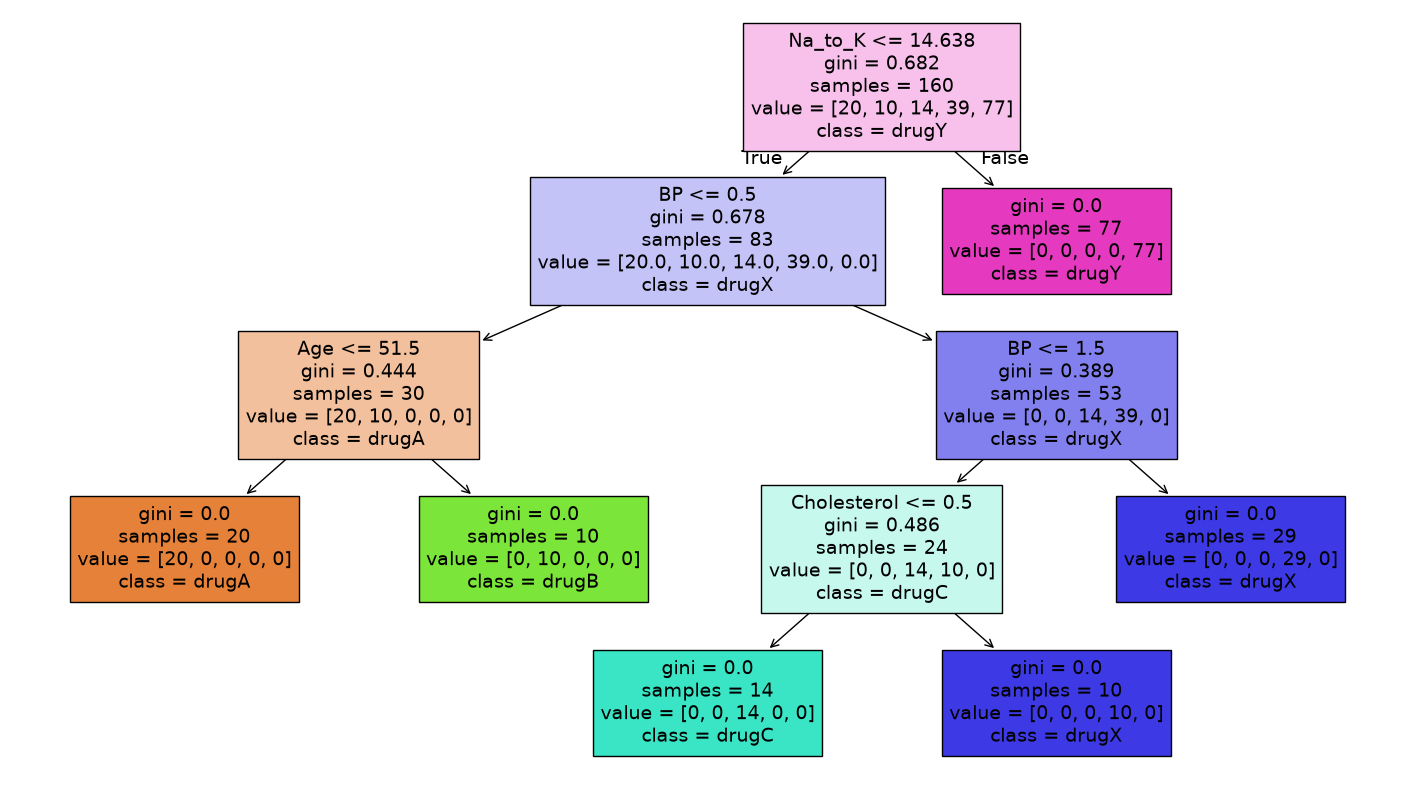

In [9]:
dtc.fit(xtrain,ytrain)
ypred=dtc.predict(xtest)
plt.figure(figsize=(18,10))
plot_tree(dtc,filled=True,feature_names=x.columns,class_names=le.classes_)
plt.show()


In [16]:
print("Train Accuracy:", dtc.score(xtrain,ytrain))
print("Test Accuracy:", dtc.score(xtest,ytest))

Train Accuracy: 1.0
Test Accuracy: 0.95


In [14]:
le.inverse_transform(dtc.predict(xtest))

array(['drugY', 'drugX', 'drugC', 'drugA', 'drugX', 'drugC', 'drugY',
       'drugB', 'drugB', 'drugY', 'drugY', 'drugX', 'drugA', 'drugY',
       'drugA', 'drugY', 'drugY', 'drugX', 'drugY', 'drugX', 'drugY',
       'drugX', 'drugY', 'drugX', 'drugY', 'drugA', 'drugX', 'drugY',
       'drugY', 'drugX', 'drugX', 'drugY', 'drugX', 'drugB', 'drugX',
       'drugX', 'drugB', 'drugB', 'drugX', 'drugY'], dtype=object)